# 03 · Model evaluation on the locked test set

**Purpose.** Judge the final model once, honestly, on 3,049 cars it never saw during cleaning decisions, feature selection, training or tuning, then explain what it learned and where it should not be trusted.

**How the numbers were produced.** `python tasks.py evaluate` runs `src/carprice/evaluate.py`: it scores the test set in a single pass (D-025), writes every table to `reports/tables/` and every figure to `reports/figures/`. This notebook only *reads* those files and interprets them, so re-running it never touches the test set again.

**Metric choices were fixed before scoring** (D-023): rupee MAE and RMSE, log-scale MAE and RMSE, R² and adjusted R² on both scales, MAPE and median absolute % error, and the share within 10% and 20%. **Headline: rupee MAE plus the within-10% share.**

In [1]:
from pathlib import Path
import sys
import warnings

from IPython.display import Image, display
import pandas as pd

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT / "src"))
# tqdm (imported by shap) warns about Jupyter widgets; the notebook does not use progress bars.
warnings.filterwarnings("ignore", message="IProgress not found")

from carprice.config import get_config
from carprice.evaluate import load_report_table

config = get_config()
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 200)


def show_figure(name: str) -> None:
    """Display reports/figures/<name>.png."""
    display(Image(filename=str(config.paths.figures_dir / f"{name}.png")))

## 1. Headline metrics for all three models

**What is checked.** Every D-023 metric for the final tuned XGBoost, the Ridge baseline and a dummy that always predicts the training median.

In [2]:
test_metrics = load_report_table("test_metrics")
test_metrics.set_index("model").T

model,Final model (tuned XGBoost),Ridge baseline,Dummy baseline (train median)
model_id,final,ridge_baseline,dummy_baseline
n_test,3049,3049,3049
mae_inr,94648,115850,385255
rmse_inr,202801,266575,807416
r2_inr,0.9328,0.8839,-0.0654
adj_r2_inr,0.9319,0.8824,-0.0654
mae_log,0.1247,0.1457,0.5016
rmse_log,0.1648,0.1881,0.6732
r2_log,0.9399,0.9216,-0.0036
adj_r2_log,0.9391,0.9206,-0.0036


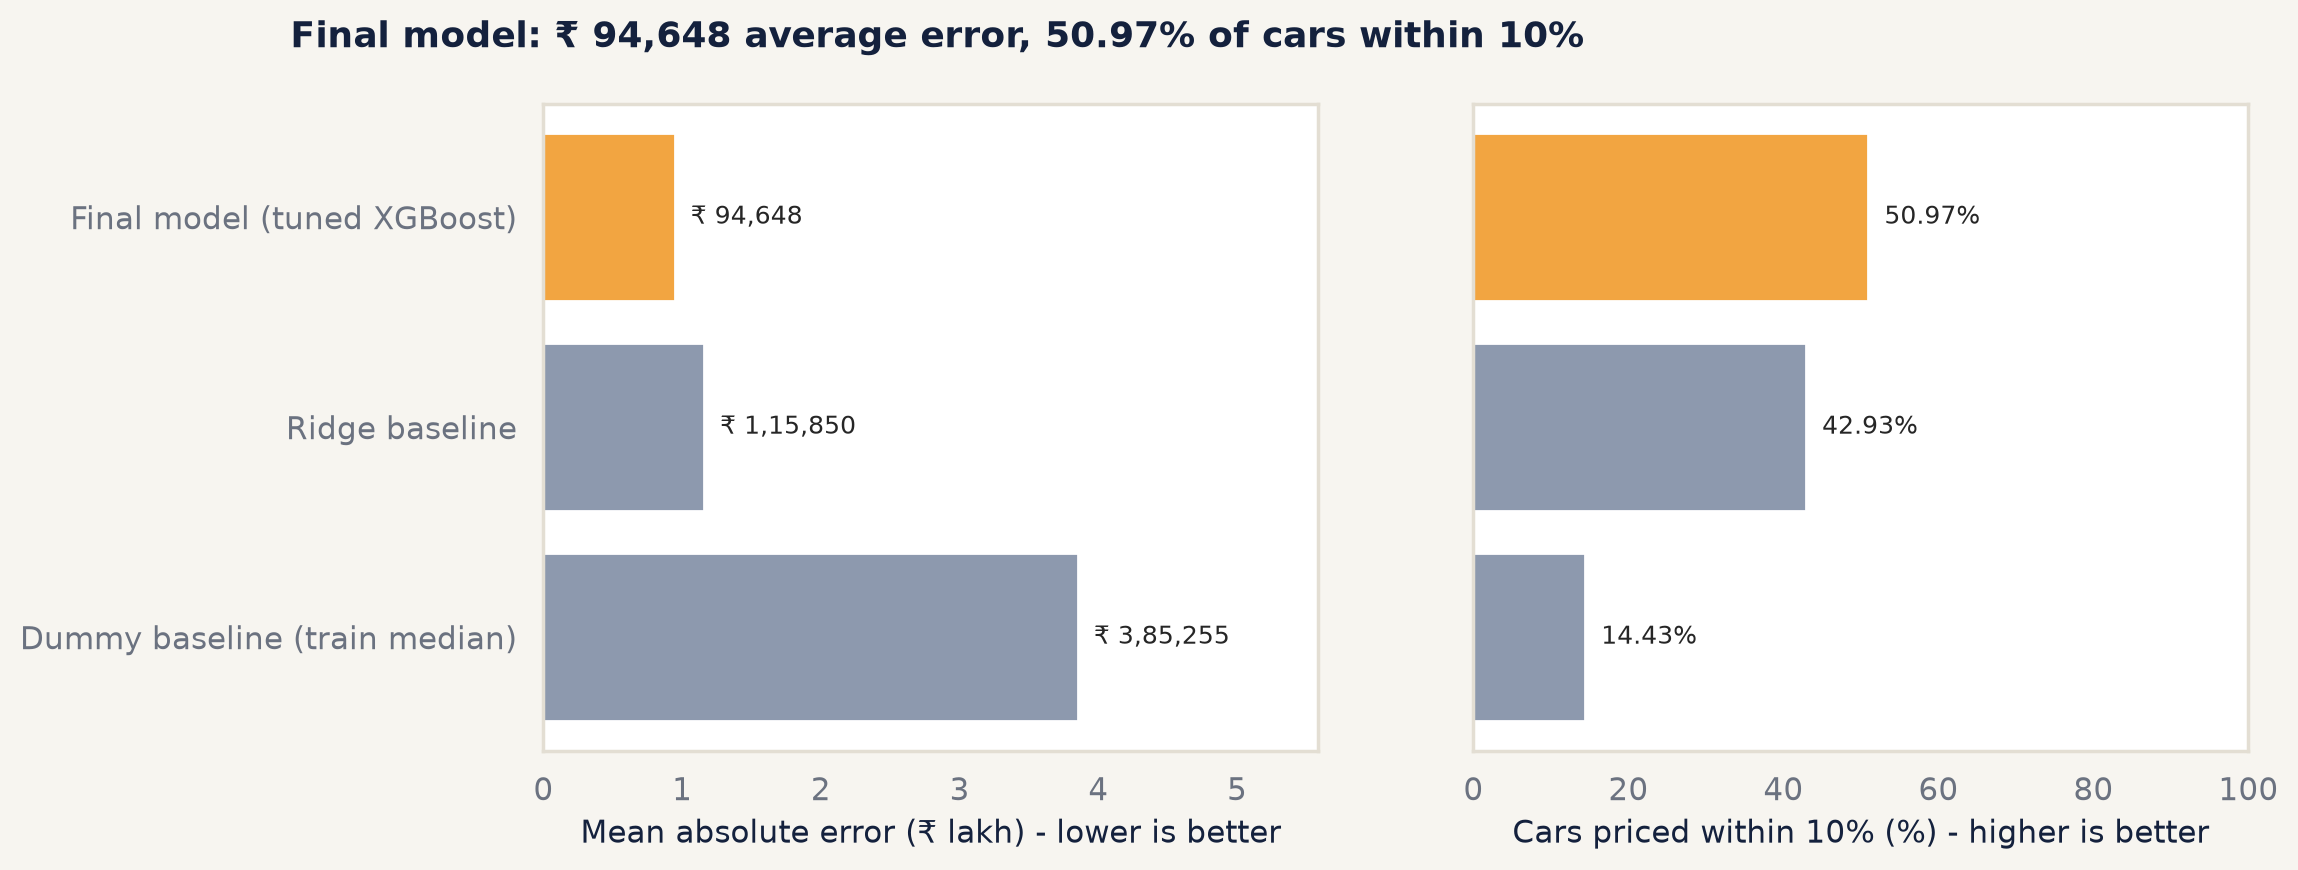

In [3]:
show_figure("eval_06_model_comparison")

**What was found.** The final model misses by ₹ 94,648 on average and prices 50.97% of cars within 10% (82.09% within 20%). Ridge manages ₹ 1,15,850 and 42.93%; the dummy ₹ 3,85,255 and 14.43%. On the log scale the model optimised, R² is 0.9399; on rupees it is 0.9328. Adjusted R² barely moves (0.9391 and 0.9319) because the test set is large relative to the number of predictors. MAPE (12.7%) is above the median absolute error (9.75%) because cheap cars with large relative misses inflate the mean.

**What it means.** Both learned models are far better than guessing; the boosted trees add a clear further gain over the linear baseline. The next cell checks whether that gain is real or a lucky split.

## 2. How certain are these numbers? (bootstrap, 1,000 resamples)

**What is checked.** The test set is resampled with replacement 1,000 times (seed 42) and the headline metrics recomputed each time; the middle 95% of the resampled values gives each 95% confidence interval.

In [4]:
load_report_table("bootstrap_ci")

,metric,bootstrap_mean,ci_low,ci_high,n_resamples,confidence_level
0,mae_inr,94695.0000,88440.0000,101444.0000,1000,0.95
1,mdape_pct,9.7800,9.3500,10.2800,1000,0.95
2,rmse_log,0.1647,0.1589,0.1702,1000,0.95
3,r2_log,0.9398,0.9348,0.9452,1000,0.95
4,mae_inr_final_minus_ridge,-21250.0000,-28252.0000,-14851.0000,1000,0.95
5,within_10pct,50.9700,49.2300,52.7100,1000,0.95
6,within_20pct,82.1000,80.8500,83.4700,1000,0.95


**What was found.** MAE lies between ₹ 88,440 and ₹ 1,01,444; the within-10% share between 49.23% and 52.71%. The final model's MAE advantage over Ridge is ₹ 21,250 with an interval of ₹ 14,851 to ₹ 28,252 (the table stores these as negative differences, final minus Ridge).

**What it means.** The interval for the gain over Ridge excludes zero, so the improvement is not an accident of which cars landed in the test set. The headline numbers are stable to within a couple of percentage points.

## 3. Overfitting check: train vs cross-validation vs test

**What is checked.** Log RMSE on the training data itself, in 5-fold out-of-fold CV (from Phase 4), and on the test set.

In [5]:
load_report_table("train_vs_test")

,split,rmse_log,mae_log,r2_log,rmse_gap_vs_cv_pct
0,train (in-sample fit),0.1387,0.1062,0.9596,-16.14
1,train (5-fold out-of-fold CV),0.1654,0.1226,0.9426,0.00
2,"test (held out, scored once)",0.1648,0.1247,0.9399,-0.36


**What was found.** In-sample RMSE is 0.1387, CV 0.1654 and test 0.1648 (a -0.36% difference from CV).

**What it means.** The model fits its own training rows more tightly than new ones, which is expected for boosted trees, but the CV estimate predicted the test score almost exactly. There is **no sign of overfitting to the tuning folds and no underfitting**; the CV numbers in the model card can be trusted as forecasts of real-world error.

## 4. Predicted vs actual, and the 80% price range

**What is checked.** Whether predictions sit on the y = x line across the whole price range, and whether the 80% interval from D-020 really contains about 80% of true prices.

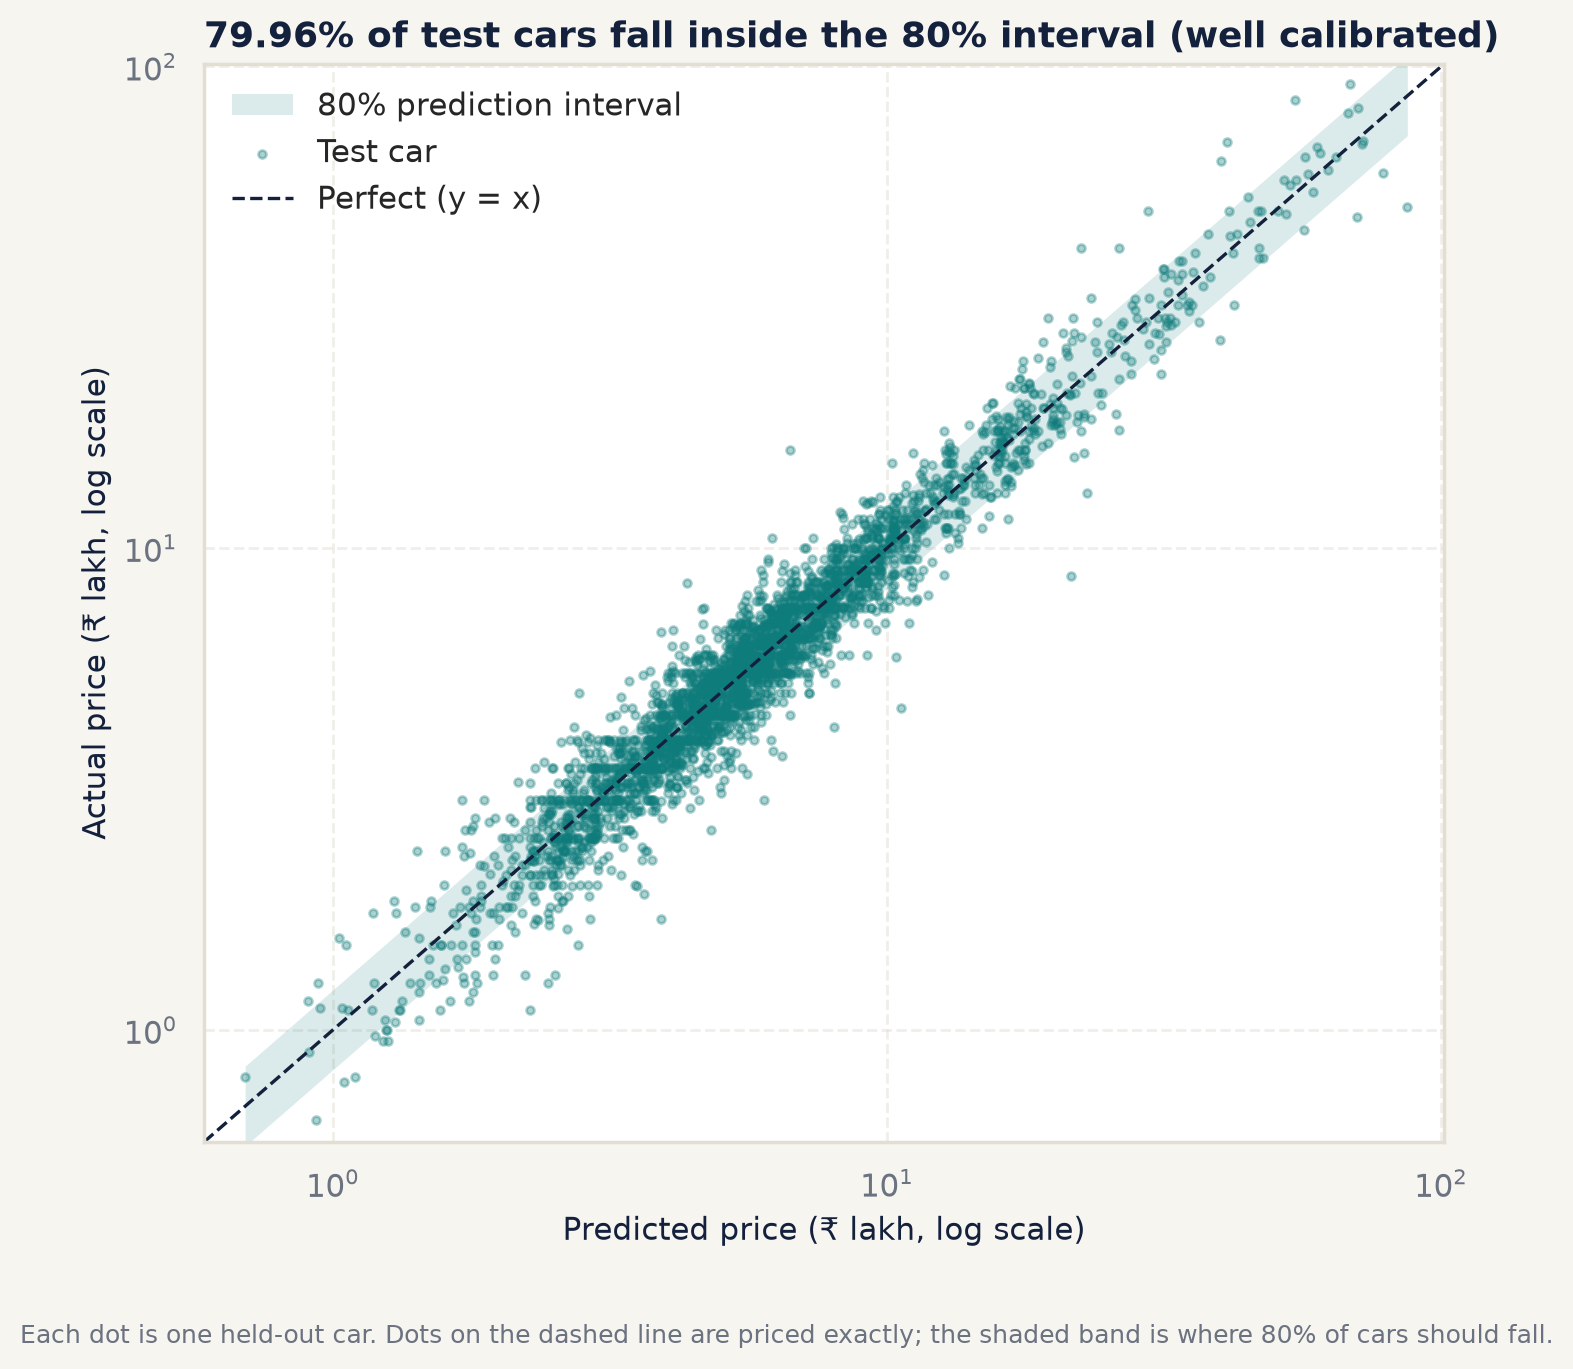

In [6]:
show_figure("eval_01_predicted_vs_actual")

In [7]:
load_report_table("interval_coverage")

,n_test,covered,nominal_pct,coverage_pct,ci_low_pct,ci_high_pct,below_interval_pct,above_interval_pct,median_width_pct_of_pred,verdict
0,3049,2438,80.0,79.96,78.5,81.34,10.07,9.97,38.44,well calibrated


**What was found.** 79.96% of test cars fall inside their interval (95% CI 78.5% to 81.34%), with misses split almost evenly: 10.07% below and 9.97% above. The median interval spans 38.44% of the predicted price.

**What it means.** The nominal 80% lies inside the confidence interval, so the interval is **well calibrated** overall. Section 6 shows this holds on average but not for every kind of car.

## 5. Residual diagnostics

**What is checked.** Bias across the price range (residuals vs predicted), the shape of the error distribution (QQ plot) and the spread of percentage errors.

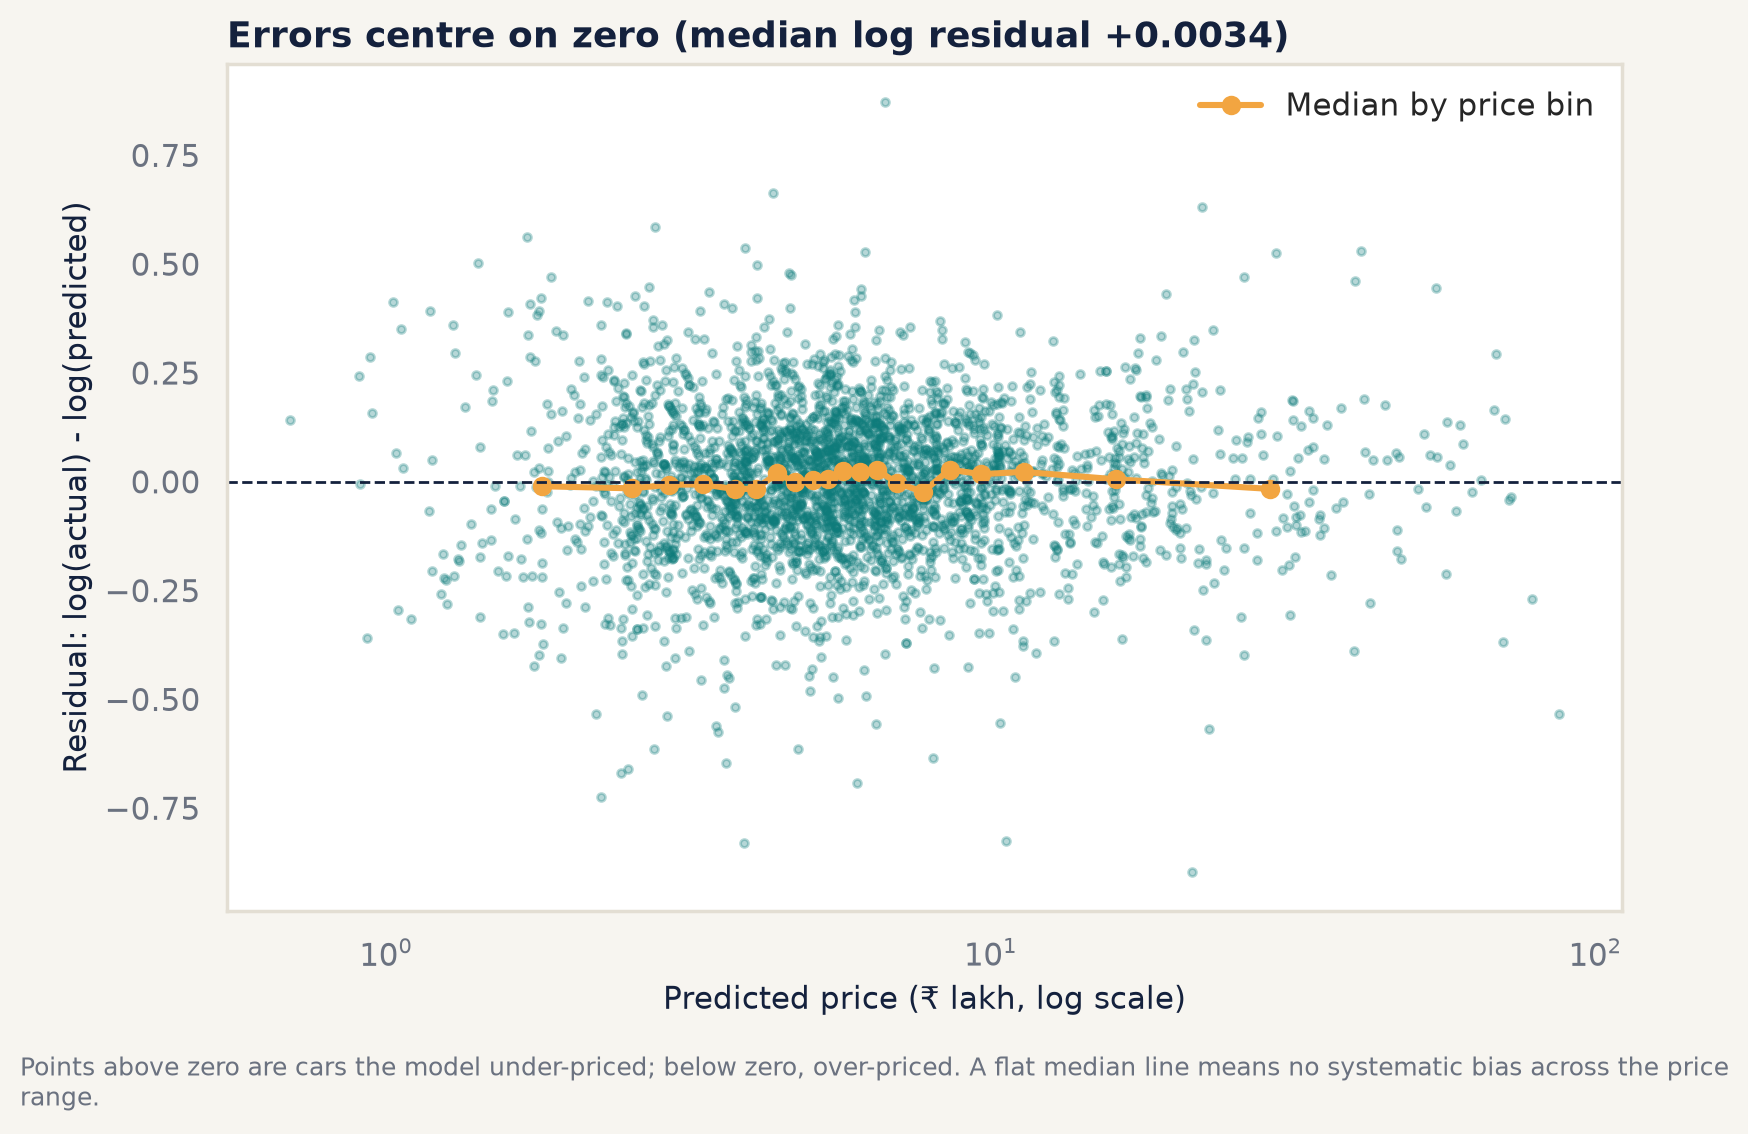

In [8]:
show_figure("eval_02_residuals_vs_predicted")

In [9]:
load_report_table("residual_stats")

,mean_log_residual,median_log_residual,std_log_residual,skewness,excess_kurtosis,share_beyond_2sd_pct,normal_share_beyond_2sd_pct
0,-0.0009,0.0034,0.1648,-0.247,1.875,5.21,4.55


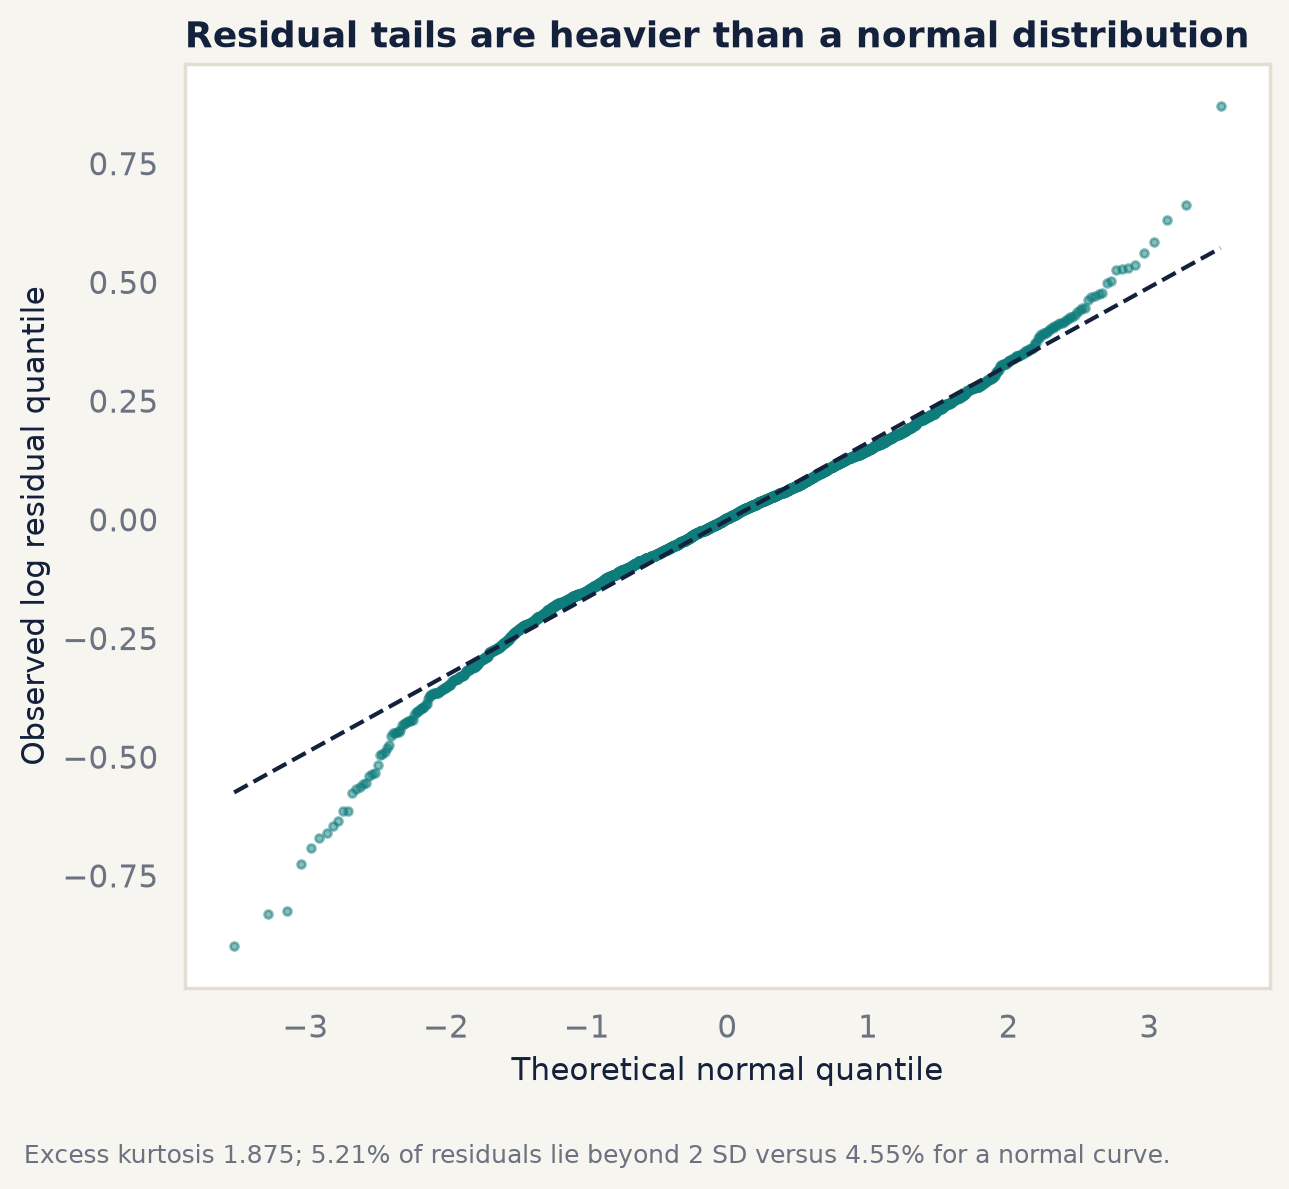

In [10]:
show_figure("eval_03_residual_qq")

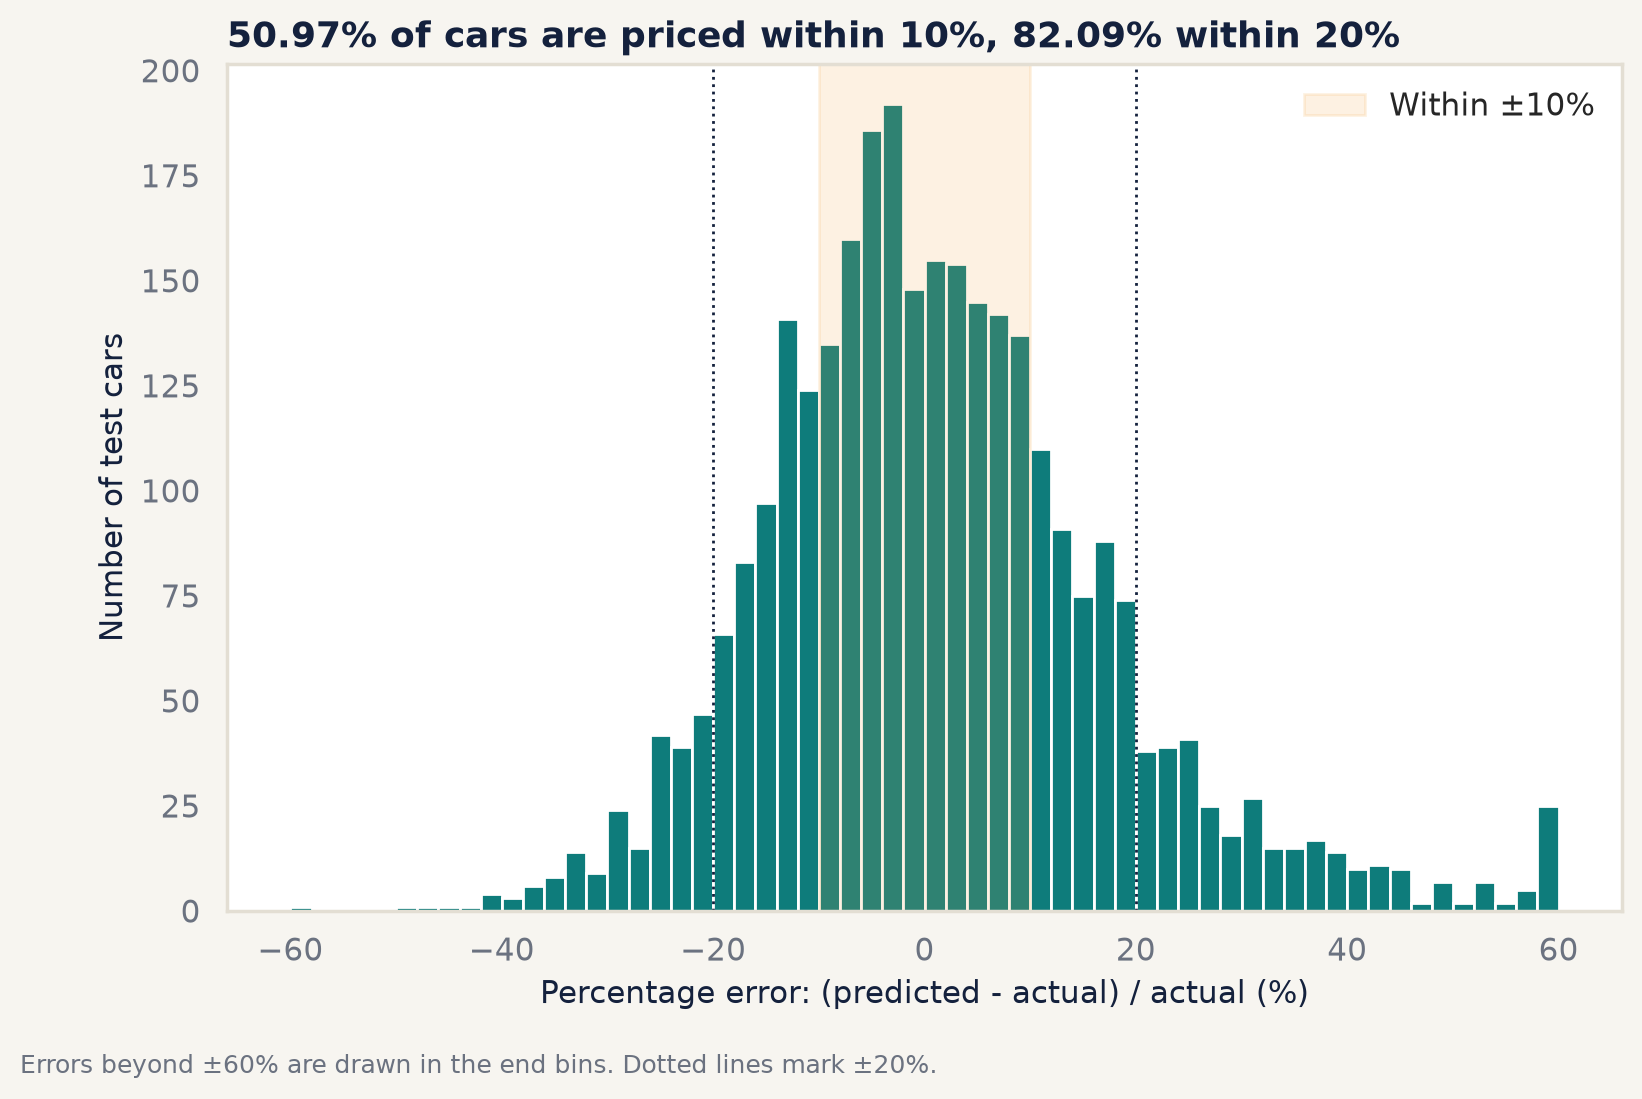

In [11]:
show_figure("eval_04_pct_error_hist")

**What was found.** The median log residual is 0.0034 and the binned medians stay flat across prices, so there is no overall bias. The tails are heavier than a normal curve: excess kurtosis 1.875 and 5.21% of residuals beyond two standard deviations against 4.55% expected.

**What it means.** Most cars are priced tightly, but a minority of large misses exists. That is why the interval in D-020 was built from empirical residual quantiles rather than a normal assumption, and why RMSE (₹ 2,02,801) is much larger than MAE.

## 6. Where the model is weak: segment analysis

**What is checked.** The same metrics within seven segmentations: price band (training-set quintiles), a luxury band above ₹20 lakh, top-10 brands, fuel, transmission, vehicle age band and seller type. The five worst segments (lowest within-10% share, at least 30 test cars, D-023) are flagged.

In [12]:
segments = load_report_table("segment_errors")
segments.sort_values(["worst_rank", "within_10pct"]).head(8)

,segmentation,segment,n_test,median_actual_inr,mae_inr,mape_pct,mdape_pct,median_signed_pct_error,interval_coverage_pct,within_10pct,within_20pct,eligible_for_ranking,worst_rank
28,Vehicle age band,12+ yrs,168,235000,60258,20.61,18.90,2.05,52.38,32.74,54.17,True,1.0
27,Vehicle age band,9-11 yrs,451,350000,87658,17.34,14.39,-0.75,65.41,33.92,68.07,True,2.0
7,Brand (top 10),Bmw,76,1975000,372189,17.36,14.94,-2.86,68.42,34.21,72.37,True,3.0
0,Price band (train quintiles),Q1: ₹0.4-3.5 lakh,650,275000,41855,17.24,12.96,7.26,68.92,39.23,70.00,True,4.0
5,Luxury band,Above ₹20 lakh,136,3000000,546266,14.62,12.18,-5.76,71.32,41.18,77.21,True,5.0
20,Fuel type,Lpg,11,175000,39199,19.25,24.31,7.13,45.45,27.27,45.45,False,NaN
13,Brand (top 10),Other brands,259,1350000,286987,15.43,11.97,-0.33,72.20,42.47,73.75,True,NaN
8,Brand (top 10),Ford,166,557500,73471,15.15,11.12,-0.47,77.71,44.58,78.92,True,NaN


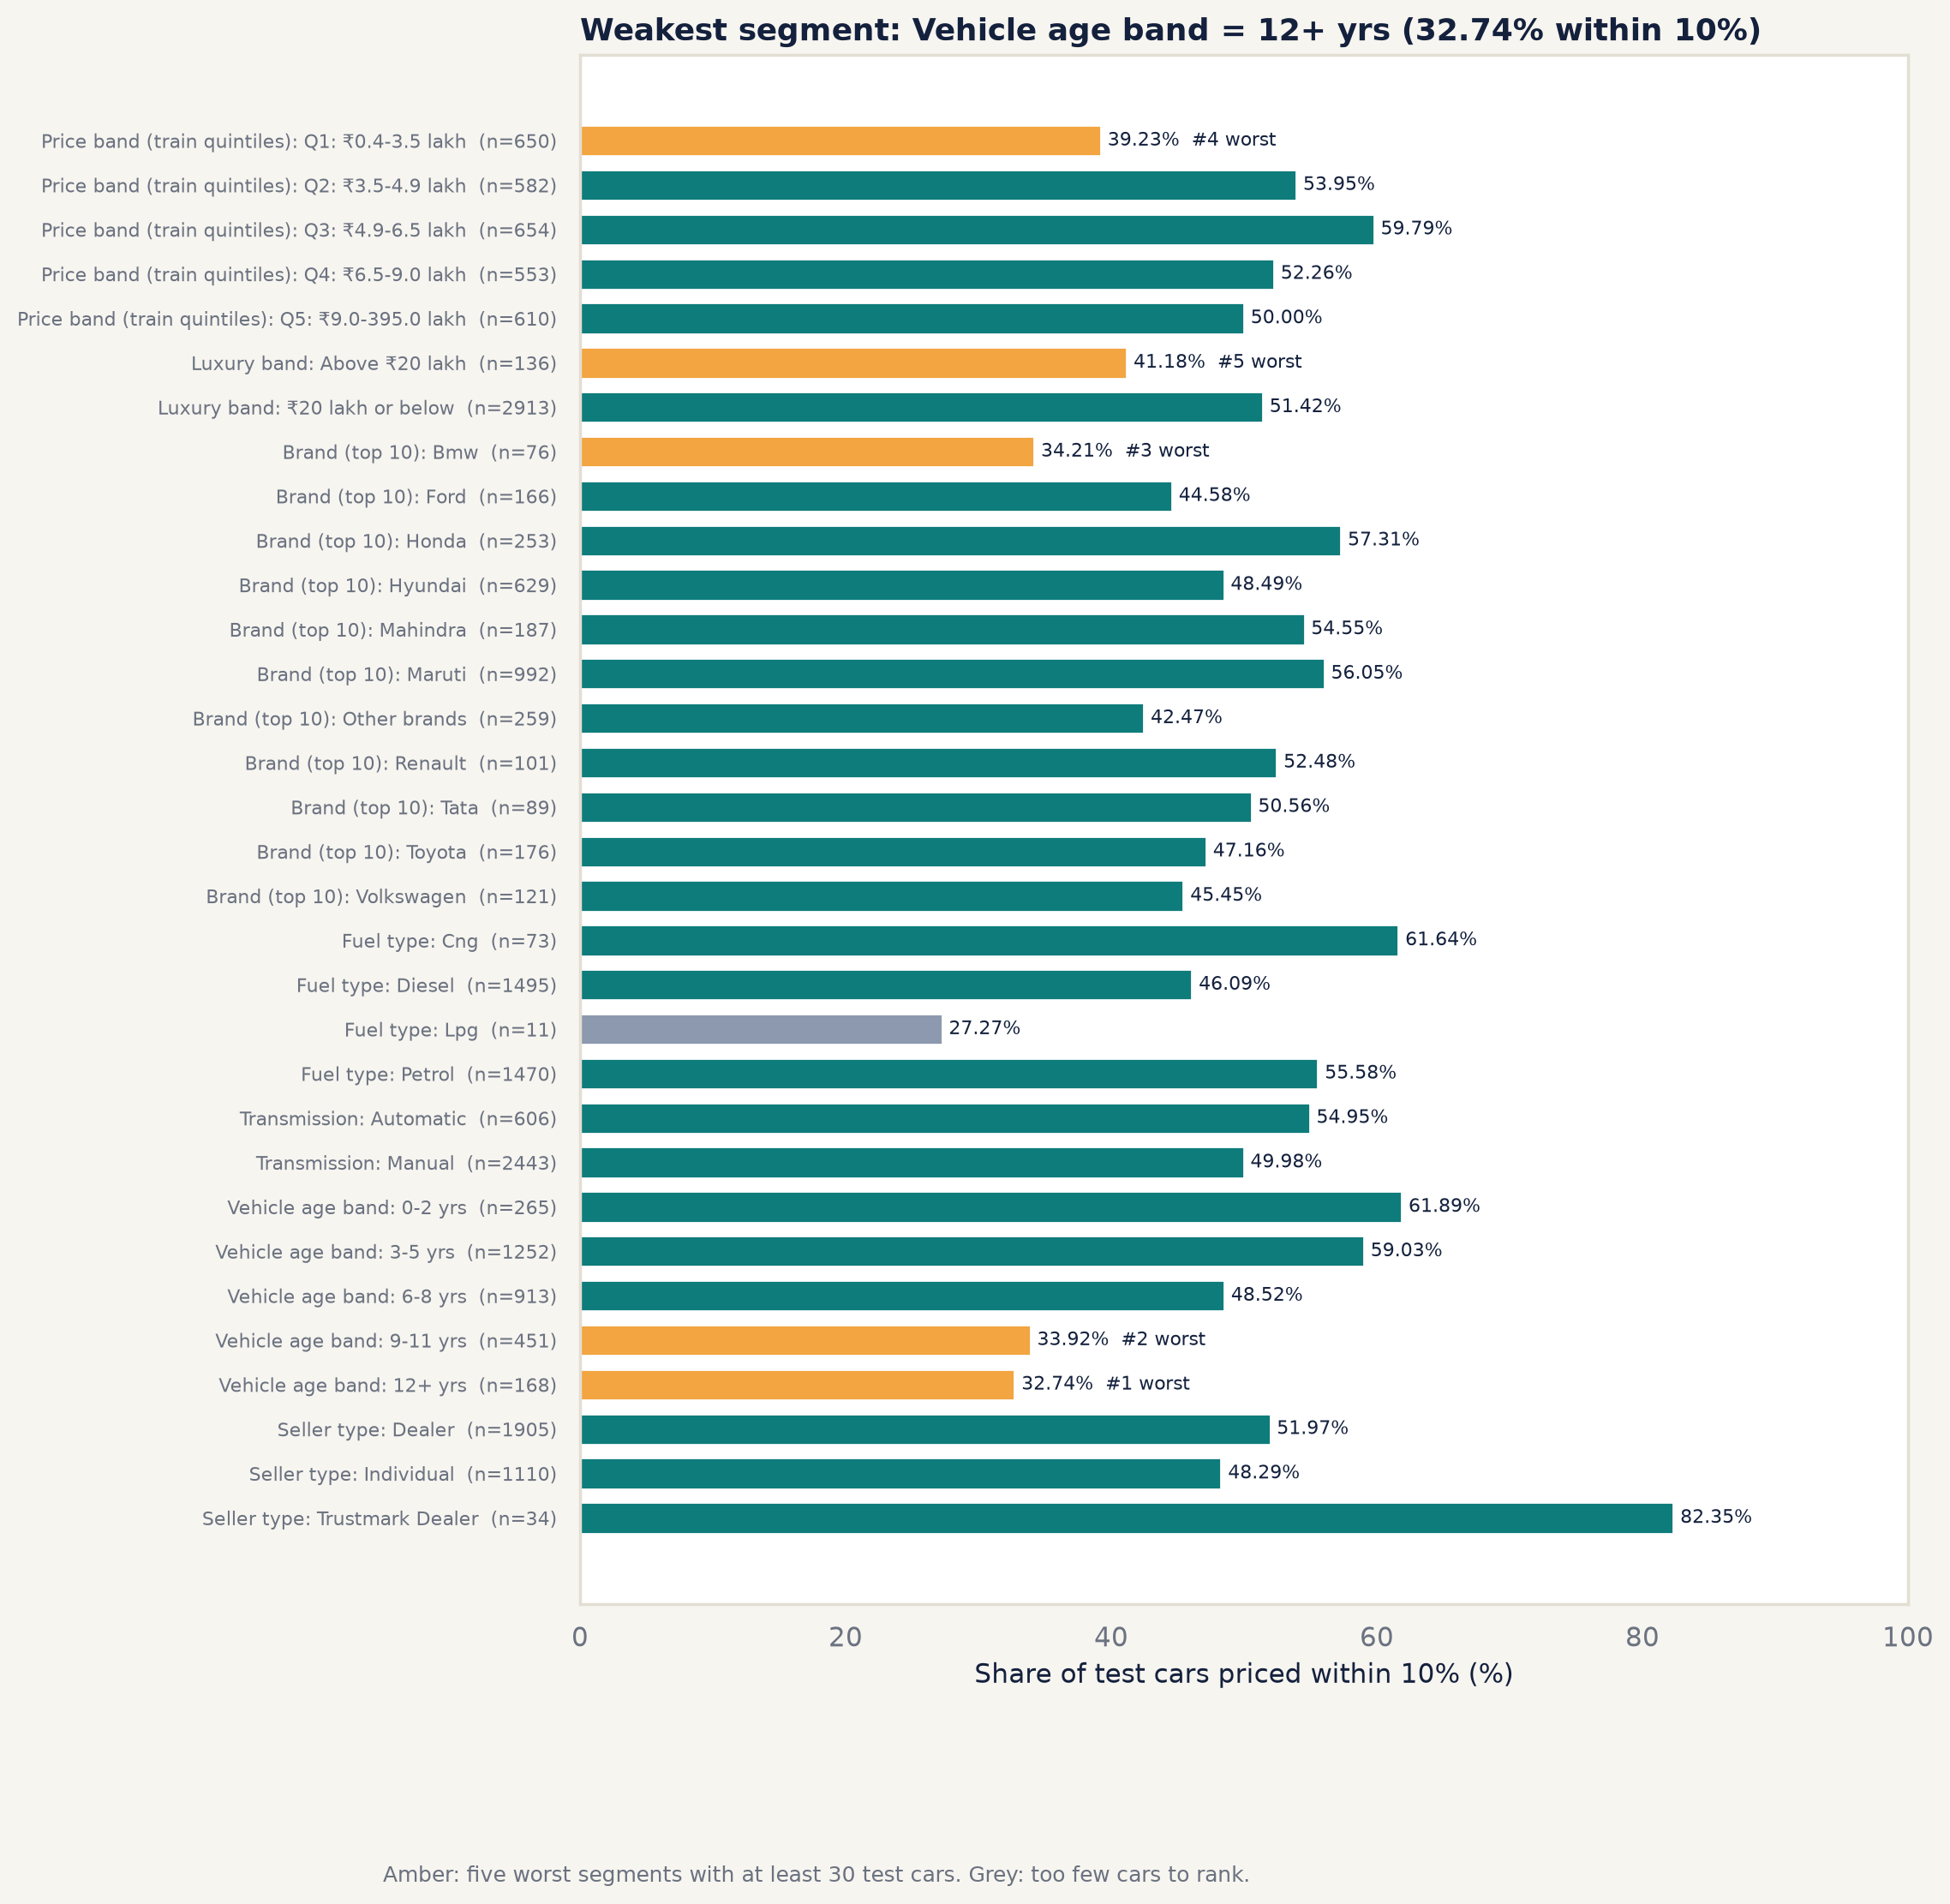

In [13]:
show_figure("eval_05_segment_within10")

In [14]:
segments[segments["segmentation"] == "Vehicle age band"][
    ["segment", "n_test", "within_10pct", "mdape_pct", "interval_coverage_pct"]
]

,segment,n_test,within_10pct,mdape_pct,interval_coverage_pct
24,0-2 yrs,265,61.89,7.66,92.45
25,3-5 yrs,1252,59.03,8.14,85.54
26,6-8 yrs,913,48.52,10.35,80.94
27,9-11 yrs,451,33.92,14.39,65.41
28,12+ yrs,168,32.74,18.90,52.38


**What was found.**
- The five worst segments are cars aged 12+ yrs (32.74% within 10%), 9-11 yrs (33.92%), Bmw (34.21%), the cheapest price band Q1: ₹0.4-3.5 lakh (39.23%) and cars above ₹20 lakh (41.18%).
- Accuracy declines with age: 61.89% within 10% at 0-2 yrs down to 32.74% at 12+ yrs.
- The cheapest cars are over-priced (median signed error +7.26%) and luxury cars under-priced (-5.76%): both are pulled toward the middle of the market.
- **Interval coverage is not uniform**: 92.45% for 0-2 year-old cars but 52.38% for 12+ years.
- LPG looks worst (27.27%) but has only 11 test cars, too few to rank.

**What it means.** The model is strongest for young, mid-priced, high-volume cars. Old cars vary in condition far more than the data can describe, and luxury cars are thin in the data. The single fixed-width interval is too generous for new cars and too tight for old ones; a later version should widen it by age band.

## 7. The 20 largest errors

**What is checked.** The 20 test cars with the largest rupee error, with every input feature, and simple counts of what they have in common.

In [15]:
load_report_table("top_errors")

,rank,brand,model,vehicle_age,km_driven,seller_type,fuel_type,transmission_type,mileage,engine,max_power,seats,km_was_capped,actual_inr,interval_low,interval_high,inside_interval,abs_error_inr,signed_pct_error,log_residual,pred_final
0,1,Mercedes-Amg,C,4,24000,Dealer,Petrol,Automatic,11.90,2996,362.07,5,False,5100000,7182766.0,10522171.0,False,3588363.0,70.36,-0.5327,8688363.0
1,2,Bmw,7,3,50000,Individual,Diesel,Automatic,16.77,2993,261.49,5,False,8500000,4497111.0,6587903.0,False,3060239.0,-36.00,0.4463,5439761.0
2,3,Land Rover,Rover,2,19000,Dealer,Diesel,Automatic,22.30,1999,177.00,5,False,6975000,3390000.0,4966076.0,False,2874414.0,-41.21,0.5312,4100586.0
3,4,Audi,Q7,4,54000,Dealer,Diesel,Automatic,12.07,2967,241.40,7,False,6350000,3307418.0,4845100.0,False,2349306.0,-37.00,0.4620,4000694.0
4,5,Land Rover,Rover,4,9500,Dealer,Diesel,Automatic,12.65,2993,296.00,5,False,9200000,5668401.0,8303750.0,False,2343431.0,-25.47,0.2940,6856569.0
5,6,Jeep,Wrangler,4,40000,Dealer,Petrol,Automatic,9.50,3604,280.00,5,False,4875000,5818151.0,8523121.0,False,2162708.0,44.36,-0.3672,7037708.0
6,7,Porsche,Cayenne,8,120000,Individual,Diesel,Automatic,15.15,2967,240.00,5,False,5000000,2444824.0,3581470.0,False,2042710.0,-40.85,0.5252,2957290.0
7,8,Mercedes-Benz,C-Class,6,24000,Dealer,Diesel,Automatic,15.80,2143,170.00,5,False,4200000,1848210.0,2707478.0,False,1964382.0,-46.77,0.6306,2235618.0
8,9,Mercedes-Benz,Gl-Class,3,15000,Dealer,Petrol,Automatic,11.50,2996,362.00,5,False,6000000,6490524.0,9508093.0,False,1851018.0,30.85,-0.2689,7851018.0
9,10,Porsche,Cayenne,9,87000,Dealer,Diesel,Automatic,15.15,2967,240.00,5,False,4200000,2166787.0,3174168.0,False,1579027.0,-37.60,0.4715,2620973.0


In [16]:
load_report_table("top_error_patterns").T

,0
n_rows,20.00
actual_above_luxury_threshold,17.00
luxury_brand,18.00
over_predicted,8.00
under_predicted,12.00
outside_interval,18.00
automatic,20.00
dealer_sellers,15.00
median_vehicle_age,4.00
median_actual_inr,4725000.00


**What was found.** These 20 cars are 0.66% of the test set but carry 12.04% of all rupee error. 18 are luxury brands, 17 sell for more than ₹20 lakh, all 20 are automatics and 18 fall outside their interval. 12 were under-priced and 8 over-priced.

**Explanation of the patterns.**
1. *Coarse model names.* The data uses labels like "Rover" for every Land Rover and "C" for a Mercedes-AMG, so an entry-level variant and a top variant with very different prices look identical to the model.
2. *Thin luxury data.* Few training examples per luxury model means the target encoding and the trees have little to go on, so these predictions shrink toward the brand average.
3. *Listing anomalies.* Some rows look like data or condition outliers, for example a Volkswagen Polo with 189 bhp listed at ₹ 8,75,000 and predicted 145.39% higher.

None of these is fixable by more tuning; they need richer data (trim and variant, condition).

## 8. What drives the predictions? Permutation importance and SHAP

**What is checked.** (a) Permutation importance on the full test set: how much error grows when one input column is shuffled (10 repeats). (b) SHAP values from `TreeExplainer` for a seeded sample of 2,000 test cars, summed over one-hot columns so each input feature has one score.

In [17]:
load_report_table("permutation_importance")

,feature,mae_inr_increase,mae_inr_increase_std,rmse_log_increase,rmse_log_increase_std
0,vehicle_age,153500.0,3710.0,0.2854,0.0033
1,model,174815.0,2883.0,0.2788,0.0045
2,max_power,94451.0,1860.0,0.1170,0.0024
3,engine,29993.0,1268.0,0.0611,0.0022
4,km_driven,19183.0,1546.0,0.0230,0.0018
5,transmission_type,15362.0,1034.0,0.0148,0.0009
6,brand,15682.0,748.0,0.0137,0.0009
7,fuel_type,6002.0,518.0,0.0074,0.0005
8,seller_type,1897.0,176.0,0.0067,0.0004
9,mileage,4123.0,388.0,0.0060,0.0005


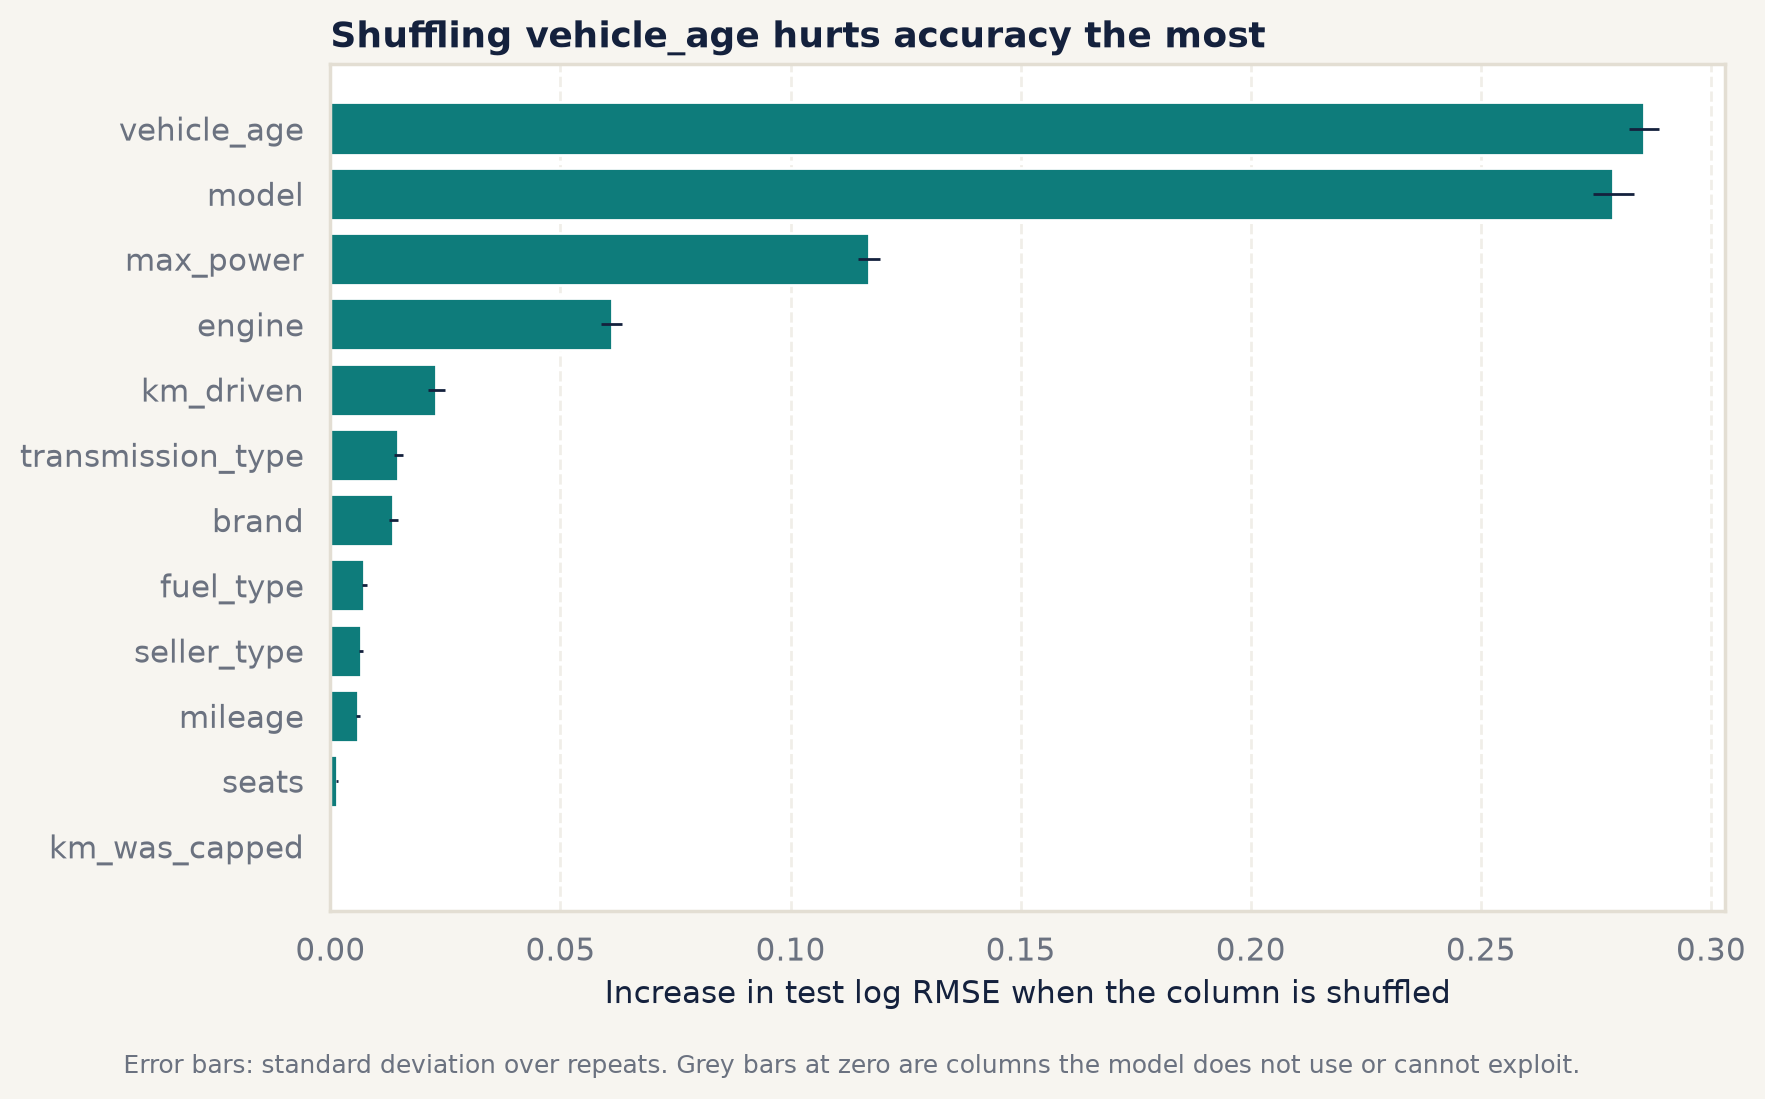

In [18]:
show_figure("eval_07_permutation_importance")

In [19]:
load_report_table("shap_importance")

,feature,mean_abs_shap_log,share_pct
0,model,0.2532,30.41
1,vehicle_age,0.1694,20.35
2,max_power,0.1064,12.78
3,engine,0.0680,8.16
4,age_x_power,0.0539,6.47
5,transmission_type,0.0429,5.15
6,km_driven,0.0415,4.98
7,fuel_type,0.0235,2.82
8,seller_type,0.0179,2.15
9,power_per_litre,0.0118,1.42


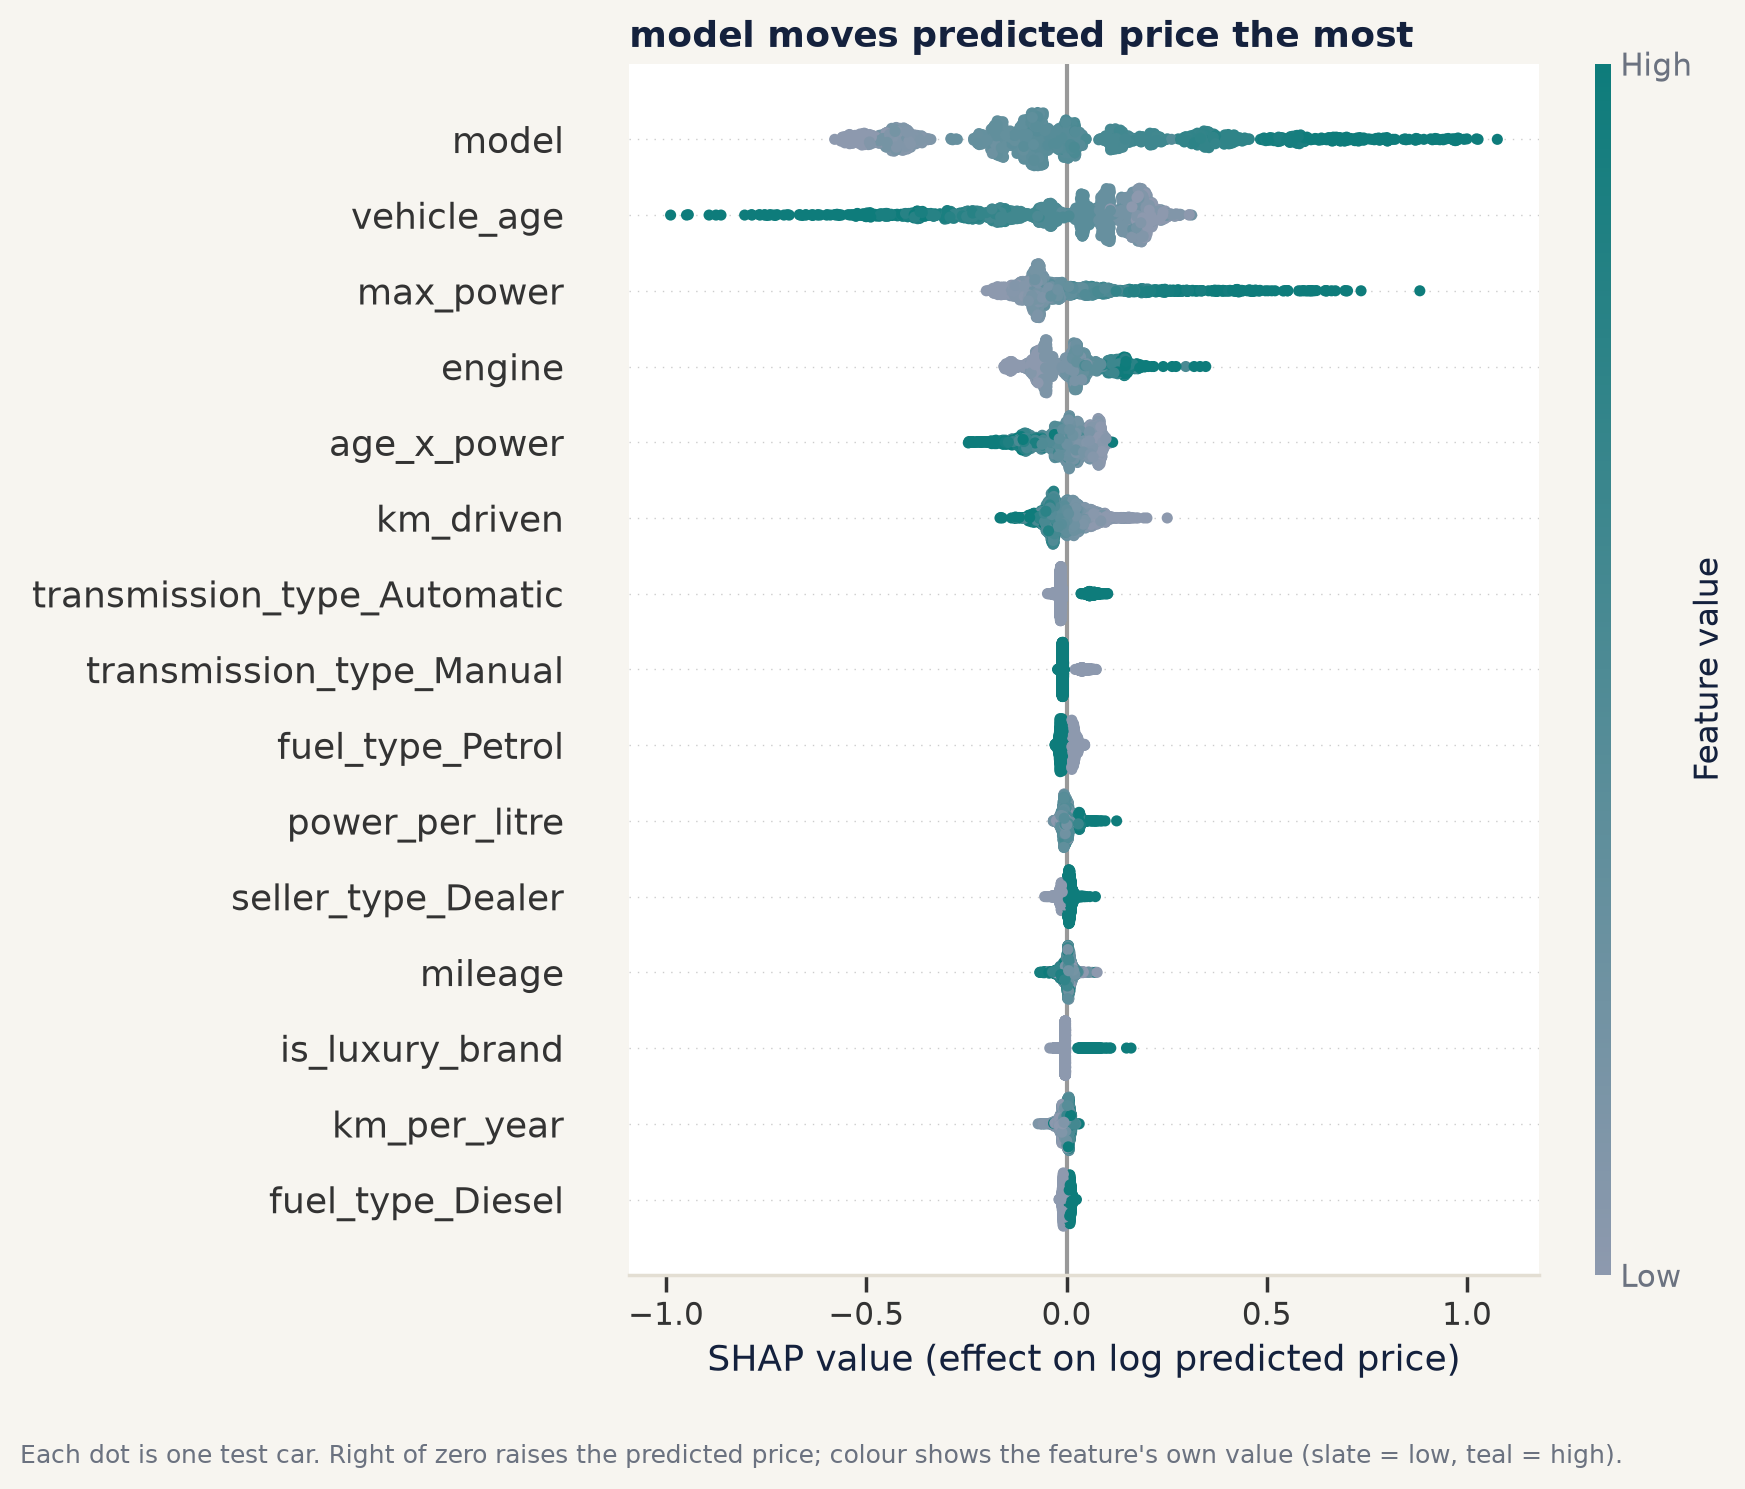

In [20]:
show_figure("shap_01_summary")

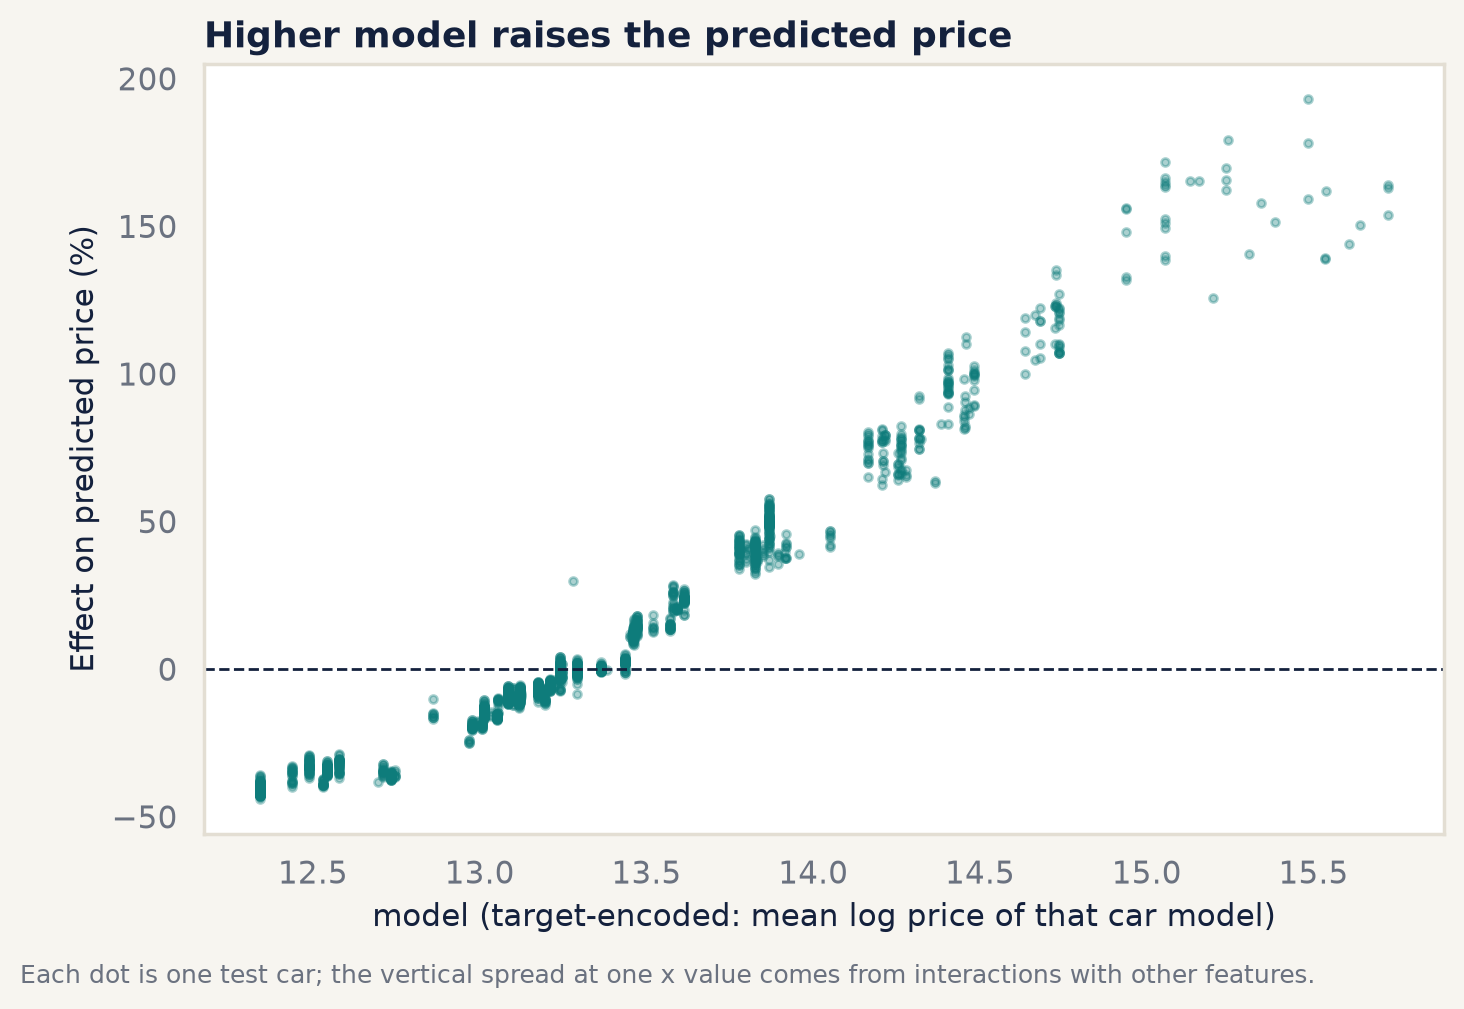

In [21]:
show_figure("shap_02_dependence_model")

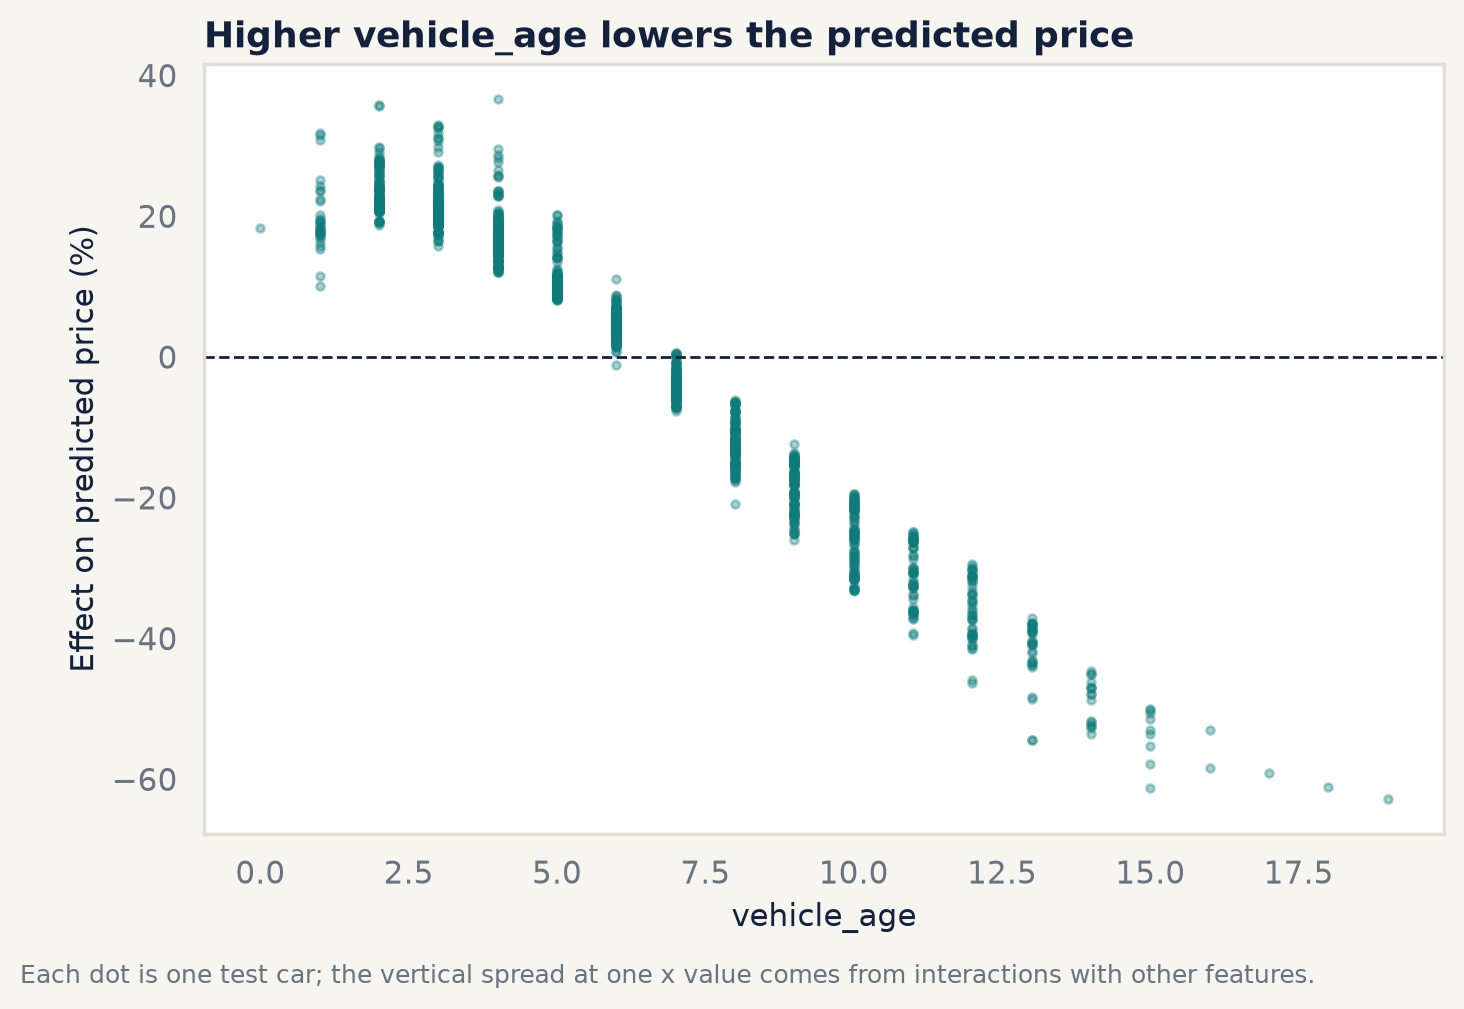

In [22]:
show_figure("shap_03_dependence_vehicle_age")

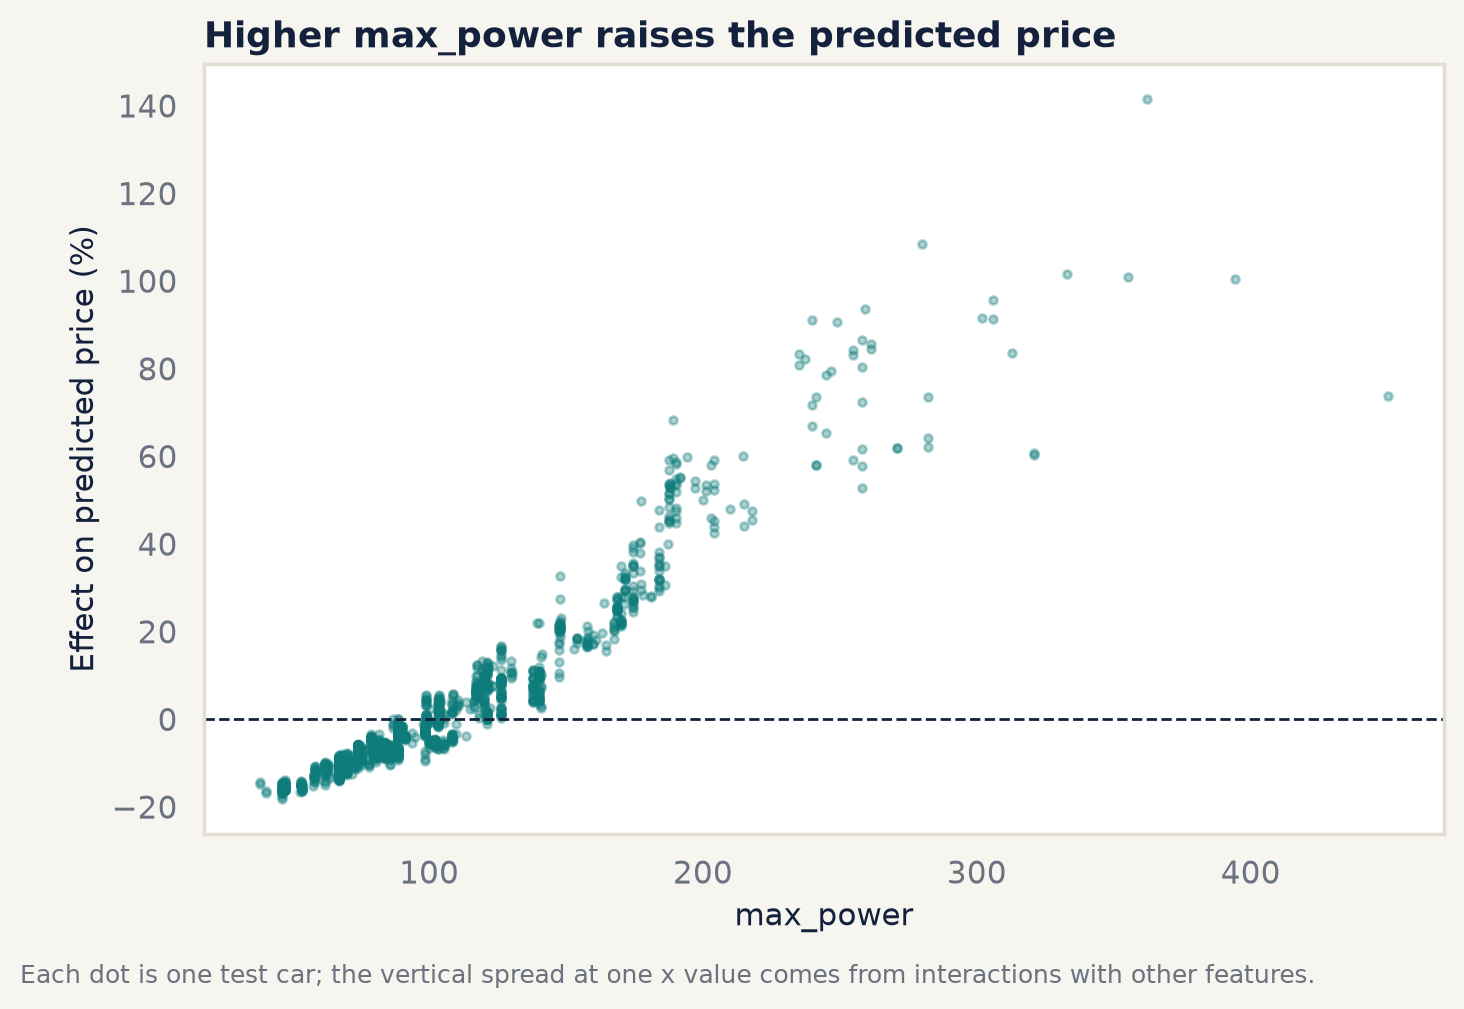

In [23]:
show_figure("shap_04_dependence_max_power")

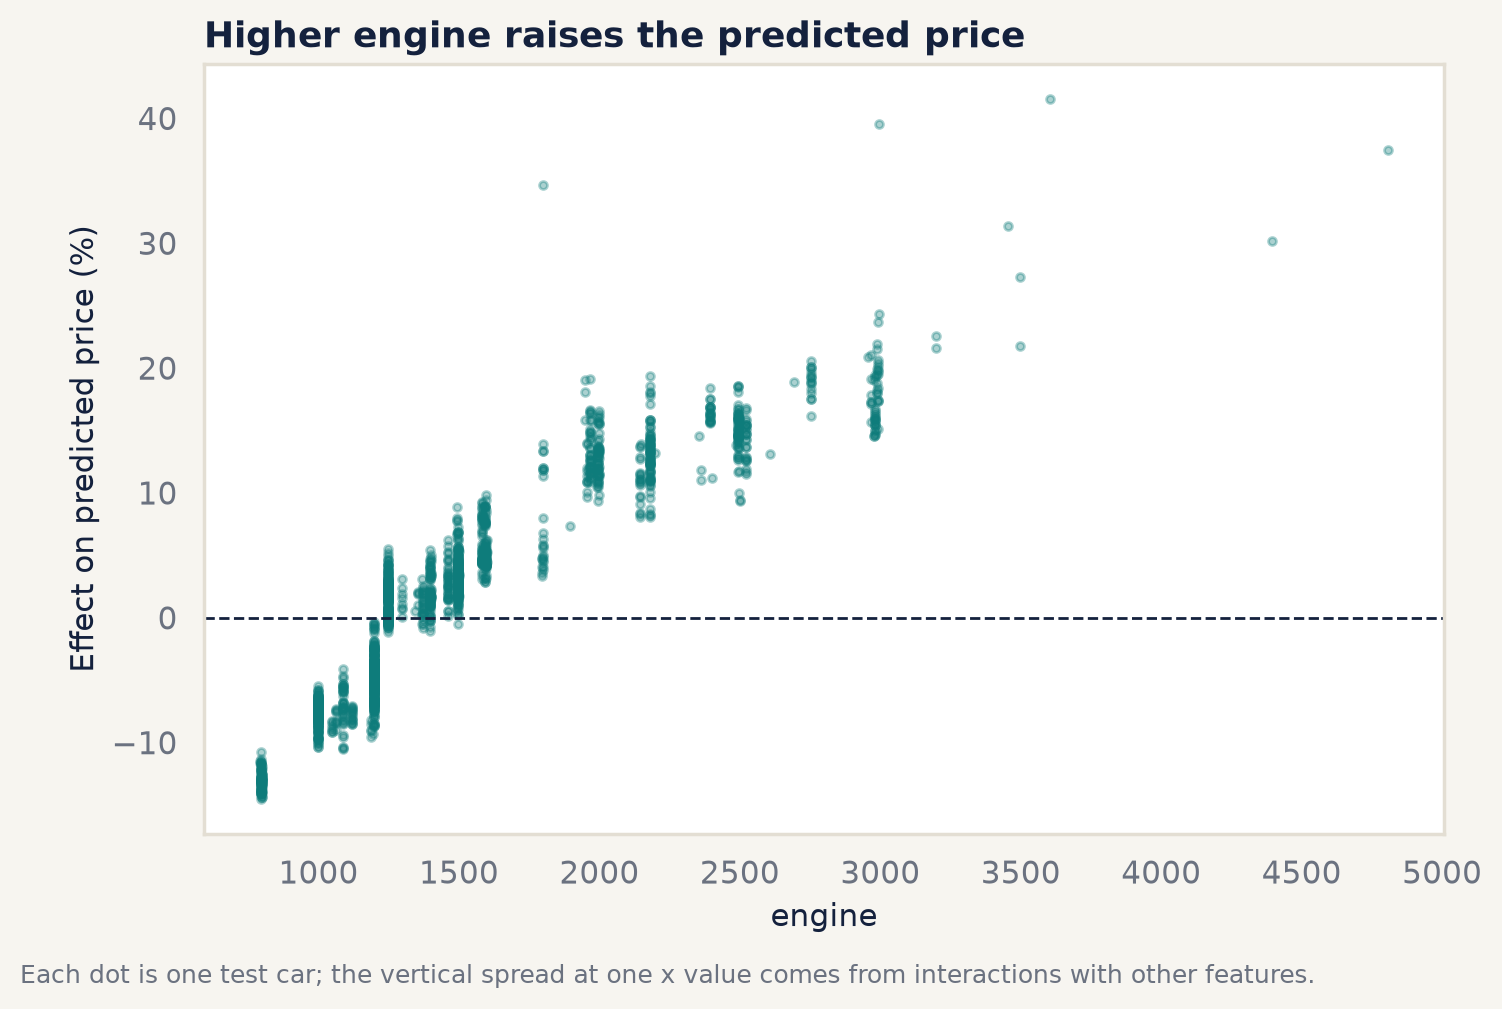

In [24]:
show_figure("shap_05_dependence_engine")

**What was found.** The four strongest drivers are `model` (30.41% of total SHAP effect), `vehicle_age` (20.35%), `max_power` (12.78%) and `engine` (8.16%). Permutation importance agrees on the top three: shuffling `vehicle_age` raises test log RMSE by 0.2854, `model` by 0.2788 and `max_power` by 0.117. `km_was_capped` scores exactly zero, confirming that the pipeline never uses it (D-024).

**In plain language.** The model prices a car mainly by *which car it is*, *how old it is* and *how powerful it is*. Each extra year lowers the predicted price steadily, and more power or a bigger engine raises it. Kilometres, transmission, fuel and seller type make smaller adjustments on top.

**Does it agree with the EDA?** Yes. The EDA found power to have the strongest rank correlation with price (Spearman 0.7211), then engine size (0.6429) and age (-0.4778). One nuance: transmission and fuel showed large raw price gaps in the EDA (median ₹ 10,50,000 automatic vs ₹ 5,00,000 manual), but the model gives them small shares (5.15% and 2.82%). The model explains most of those gaps through power, engine and car model, which differ systematically between automatics and manuals. This matches the EDA hypothesis tests, where the automatic premium shrank in the middle power bands (rank-biserial 0.315 and 0.257) compared with the top band (0.608).

## 9. Verdict

**Is the model good enough for its purpose?** Yes, as a *first-opinion price guide for mainstream used cars*. Across the test set it misses by ₹ 94,648 on average, prices 50.97% of cars within 10% and 82.09% within 20%. Its 80% price range is honest on average (79.96% coverage) and its test error matches cross-validation, so these figures should hold for new listings from the same market.

**Where users must not trust it:**
- **Luxury cars** (above ₹20 lakh, and brands such as Bmw): only 41.18% and 34.21% within 10%, and the largest errors are concentrated here.
- **Old cars** (9 years or more): about a third within 10%, and the 80% range covers only 52.38% of 12+ year-old cars.
- **Rare models and fuels** (for example LPG with 11 test cars): too little data to judge.
- **Very cheap cars** (under ₹3.5 lakh) tend to be over-priced (median +7.26%).

The GUI should show these warnings next to the estimate whenever an input falls into one of these groups.

**What would improve it:**
1. *Richer data:* trim and variant (the biggest single fix for luxury errors), condition and accident history, service record, city, colour and number of owners.
2. *More examples* of luxury and older cars.
3. *Intervals that adapt* to vehicle age and price band instead of one global width.
4. *Small modelling fixes* already logged: use `km_was_capped` (D-024), and give the Ridge baseline one-hot `model` encoding (D-014). Any of these would require a fresh test set (D-025).